In [1]:
!pip -q install kagglehub
import os, re, gc, time, copy, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display
import torch, torch.nn as nn, torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as tvm
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, roc_curve, auc, roc_auc_score, f1_score,
                             precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize
import kagglehub
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [2]:
SEED = 42
IMG = 128
BATCH = 32            # reduce to 16 if you get CUDA out-of-memory errors
EPOCHS = 25           # maximum epochs for final training (early stopping applies)
PATIENCE = 6          # early-stopping patience on validation loss
TUNE_EPOCHS = 5       # epochs per hyperparameter trial
TUNE_PATIENCE = 3
RUN_TUNING = True     # validation-based hyperparameter search
CLASSES = ['Normal', 'Ischemia', 'Bleeding']
NC = len(CLASSES)

# ImageNet statistics adapted to single-channel CT (mean of the RGB statistics)
NORM_MEAN = float(np.mean([0.485, 0.456, 0.406]))
NORM_STD = float(np.mean([0.229, 0.224, 0.225]))

OUT_DIR = 'outputs'
MODEL_DIR = os.path.join(OUT_DIR, 'models')
PLOT_DIR = os.path.join(OUT_DIR, 'plots')
for d in (OUT_DIR, MODEL_DIR, PLOT_DIR):
    os.makedirs(d, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
torch.set_num_threads(os.cpu_count())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device:', device)

Device: cuda


In [3]:
DATA_ROOT = kagglehub.dataset_download("ozguraslank/brain-stroke-ct-dataset")
print('Path to dataset files:', DATA_ROOT)

100%|██████████| 1.41G/1.41G [00:23<00:00, 65.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ozguraslank/brain-stroke-ct-dataset/versions/3


In [4]:
EXT = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')
SKIP = re.compile(r'overlay|mask|segment|annot|label', re.I)
PID_RE = re.compile(r'(?:patient|pat|pt|subject|sub|case|hasta|pid)[ _\-]?0*(\d+)', re.I)

def infer_label(p):
    parts = os.path.relpath(p, DATA_ROOT).split(os.sep)[:-1]
    for part in parts:
        pl = part.lower()
        if re.search(r'normal|no[ _-]?stroke|healthy', pl): return 0
        if re.search(r'isch|iskem', pl): return 1
        if re.search(r'bleed|hemor|haemor|kanama', pl): return 2
    return None

def infer_patient(p):
    m = PID_RE.search(os.path.relpath(p, DATA_ROOT))
    return m.group(1) if m else None

rows = []
for dp, dn, fn in os.walk(DATA_ROOT):
    if SKIP.search(os.path.relpath(dp, DATA_ROOT)):
        continue
    for f in sorted(fn):
        if f.lower().endswith(EXT):
            p = os.path.join(dp, f)
            lab = infer_label(p)
            if lab is not None:
                rows.append((p, lab, infer_patient(p)))

df = pd.DataFrame(rows, columns=['path', 'label', 'patient'])
df['class'] = df['label'].map(dict(enumerate(CLASSES)))
print('Total images:', len(df))
print(df['class'].value_counts())
print(df.groupby('class')['path'].apply(lambda s: sorted({os.path.relpath(os.path.dirname(x), DATA_ROOT) for x in s})[:3]))
assert df['label'].nunique() == NC, 'Could not detect all 3 classes - check folder names printed above'

coverage = df['patient'].notna().mean()
n_patients = df['patient'].nunique()
USE_GROUPS = coverage >= 0.95 and n_patients >= 50
print(f'\nPatient IDs found for {coverage*100:.1f}% of images ({n_patients} unique IDs). Example file names:')
print(df['path'].map(os.path.basename).head(5).tolist())
if USE_GROUPS:
    print('-> Patient-level split (StratifiedGroupKFold): no patient appears in more than one subset.')
else:
    print('-> No usable patient IDs in paths/file names. Falling back to stratified image-level splitting.')
    print('   LIMITATION: slices from the same patient may land in different subsets, which can make')
    print('   validation/test scores optimistic. Results should be read with this in mind.')

Total images: 6650
class
Normal      4427
Ischemia    1130
Bleeding    1093
Name: count, dtype: int64
class
Bleeding    [Brain_Stroke_CT_Dataset/Bleeding/PNG]
Ischemia    [Brain_Stroke_CT_Dataset/Ischemia/PNG]
Normal        [Brain_Stroke_CT_Dataset/Normal/PNG]
Name: path, dtype: object

Patient IDs found for 0.0% of images (0 unique IDs). Example file names:
['10003.png', '10017.png', '10024.png', '10028.png', '10038.png']
-> No usable patient IDs in paths/file names. Falling back to stratified image-level splitting.
   LIMITATION: slices from the same patient may land in different subsets, which can make
   validation/test scores optimistic. Results should be read with this in mind.


Array shape: (6650, 128, 128)
Train/Val/Test: 4655 997 998
Class counts (train/val/test): [3099  791  765] [664 169 164] [664 170 164]


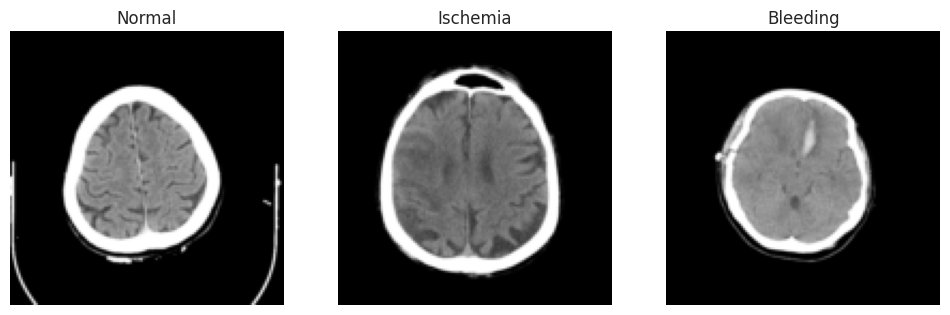

In [5]:
def load_img(p):
    return np.asarray(Image.open(p).convert('L').resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)

with ThreadPoolExecutor(8) as ex:
    X = np.stack(list(ex.map(load_img, df['path'].tolist())))
y = df['label'].values
print('Array shape:', X.shape)

if USE_GROUPS:
    groups = df['patient'].fillna(pd.Series('img_' + df.index.astype(str), index=df.index)).values
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
    folds = [te for _, te in sgkf.split(X, y, groups)]
    te_idx, va_idx = folds[0], folds[1]
    tr_idx = np.concatenate(folds[2:])
    assert not (set(groups[tr_idx]) & set(groups[va_idx])) and not (set(groups[tr_idx]) & set(groups[te_idx])) \
        and not (set(groups[va_idx]) & set(groups[te_idx])), 'Patient overlap between splits'
else:
    idx = np.arange(len(y))
    tr_idx, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
    va_idx, te_idx = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)

X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr_idx], y[tr_idx], X[va_idx], y[va_idx], X[te_idx], y[te_idx]
print('Train/Val/Test:', len(y_tr), len(y_va), len(y_te))
print('Class counts (train/val/test):', np.bincount(y_tr), np.bincount(y_va), np.bincount(y_te))

class CTSet(Dataset):
    def __init__(self, X, y, train=False):
        self.X = torch.from_numpy(X).unsqueeze(1)
        self.y = torch.from_numpy(y).long()
        self.train = train
        self.aug = T.Compose([
            T.RandomAffine(degrees=10, translate=(0.06, 0.06), scale=(0.92, 1.08)),
            T.RandomHorizontalFlip(),
            T.ColorJitter(brightness=0.15, contrast=0.15)])
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].float() / 255.
        if self.train: x = self.aug(x)
        return (x - NORM_MEAN) / NORM_STD, self.y[i]

def make_loaders(batch=BATCH):
    pin = torch.cuda.is_available()
    return (DataLoader(CTSet(X_tr, y_tr, True), batch_size=batch, shuffle=True, num_workers=0, pin_memory=pin, drop_last=False),
            DataLoader(CTSet(X_va, y_va), batch_size=batch, shuffle=False, num_workers=0, pin_memory=pin),
            DataLoader(CTSet(X_te, y_te), batch_size=batch, shuffle=False, num_workers=0, pin_memory=pin))

train_loader, val_loader, test_loader = make_loaders(BATCH)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))bbbbbjbvbvjbj
for i, c in enumerate(CLASSES):
    ax[i].imshow(X[np.where(y == i)[0][0]], cmap='gray'); ax[i].set_title(c); ax[i].axis('off')
plt.show()

In [6]:
def load_resnet():
    try:
        m = tvm.resnet18(weights=tvm.ResNet18_Weights.DEFAULT)
    except Exception as e:
        print('Pretrained weights unavailable, training from scratch:', e)
        m = tvm.resnet18(weights=None)
    w = m.conv1.weight.data.sum(1, keepdim=True)
    m.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
    m.conv1.weight.data = w
    return m

def resnet_stem(upto):
    m = load_resnet()
    layers = [m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3]
    c = 256
    if upto == 4:
        layers.append(m.layer4); c = 512
    return nn.Sequential(*layers), c

class CNN(nn.Module):
    def __init__(self, nc=NC):
        super().__init__()
        self.stem, c = resnet_stem(4)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
                                  nn.Linear(c, 128), nn.ReLU(True), nn.Dropout(0.2), nn.Linear(128, nc))
    def forward(self, x): return self.head(self.stem(x))

class SeqNet(nn.Module):
    def __init__(self, kind, hidden=128, layers=2, nc=NC):
        super().__init__()
        self.kind = kind
        self.stem, c = resnet_stem(3)
        self.proj = nn.Sequential(nn.Linear(c * (IMG // 16), 256), nn.ReLU(True), nn.Dropout(0.3))
        self.bi = kind == 'bilstm'
        if kind == 'rnn':
            self.rnn = nn.RNN(256, hidden, layers, batch_first=True, dropout=0.2, nonlinearity='tanh')
        else:
            self.rnn = nn.LSTM(256, hidden, layers, batch_first=True, dropout=0.2, bidirectional=self.bi)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(hidden * (2 if self.bi else 1), nc))
    def forward(self, x):
        f = self.stem(x)
        B, C, H, W = f.shape
        s = self.proj(f.permute(0, 2, 1, 3).reshape(B, H, C * W))
        _, h = self.rnn(s)
        h = h[0] if isinstance(h, tuple) else h
        feat = torch.cat([h[-2], h[-1]], 1) if self.bi else h[-1]
        return self.head(feat)

def grid_adj(n):
    N = n * n
    A = torch.zeros(N, N)
    for r in range(n):
        for c in range(n):
            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):
                    rr, cc = r + dr, c + dc
                    if 0 <= rr < n and 0 <= cc < n:
                        A[r * n + c, rr * n + cc] = 1
    d = A.sum(1)
    return A / d.sqrt()[:, None] / d.sqrt()[None, :]

class GCNLayer(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.lin = nn.Linear(i, o); self.bn = nn.BatchNorm1d(o)
    def forward(self, x, A):
        x = self.lin(torch.matmul(A, x))
        B, N, D = x.shape
        return Fn.relu(self.bn(x.reshape(B * N, D)).reshape(B, N, D))

class GNN(nn.Module):
    def __init__(self, hidden=128, nc=NC):
        super().__init__()
        self.stem, c = resnet_stem(3)
        n = IMG // 16
        self.register_buffer('A', grid_adj(n))
        self.inp = nn.Linear(c, hidden)
        self.pos = nn.Parameter(torch.zeros(1, n * n, hidden))
        self.gcn = nn.ModuleList([GCNLayer(hidden, hidden) for _ in range(3)])
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(hidden * 2, 128), nn.ReLU(True),
                                  nn.Dropout(0.3), nn.Linear(128, nc))
    def forward(self, x):
        f = self.stem(x)
        B, C, H, W = f.shape
        h = self.inp(f.flatten(2).transpose(1, 2)) + self.pos
        for layer in self.gcn:
            h = h + layer(h, self.A.to(h.dtype))
        return self.head(torch.cat([h.mean(1), h.max(1)[0]], 1))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [7]:
criterion = nn.CrossEntropyLoss()
results, tuning_log = {}, []

BUILDERS = {
    'CNN': lambda c: CNN(),
    'RNN': lambda c: SeqNet('rnn', hidden=c.get('hidden', 128)),
    'GNN': lambda c: GNN(hidden=c.get('hidden', 128)),
    'LSTM': lambda c: SeqNet('lstm', hidden=c.get('hidden', 128)),
    'BiLSTM': lambda c: SeqNet('bilstm', hidden=c.get('hidden', 128)),
}
GRIDS = {
    'CNN': [dict(lr=1e-3, wd=1e-4), dict(lr=3e-4, wd=1e-4), dict(lr=3e-4, wd=1e-2)],
    'RNN': [dict(lr=1e-3, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=256)],
    'GNN': [dict(lr=1e-3, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=256)],
    'LSTM': [dict(lr=1e-3, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=256)],
    'BiLSTM': [dict(lr=1e-3, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=128), dict(lr=3e-4, wd=1e-4, hidden=256)],
}

def free_memory():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def evaluate(model, loader):
    model.eval(); tl = 0.; probs = []; ys = []
    with torch.no_grad():
        for x, t in loader:
            x, t = x.to(device, non_blocking=True), t.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            out = out.float()
            tl += criterion(out, t).item() * x.size(0)
            probs.append(torch.softmax(out, 1).cpu().numpy()); ys.append(t.cpu().numpy())
    probs = np.concatenate(probs); ys = np.concatenate(ys); yp = probs.argmax(1)
    return tl / len(ys), float((yp == ys).mean()), float(f1_score(ys, yp, average='macro')), probs, ys

def fit(model, lr, wd, epochs, patience, tag, verbose=True):
    # uses ONLY train + validation data; checkpoint = epoch with lowest validation loss
    model = model.to(device)
    sp = list(model.stem.parameters()); ids = {id(p) for p in sp}
    rest = [p for p in model.parameters() if id(p) not in ids]
    opt = torch.optim.AdamW([{'params': sp, 'lr': lr * 0.3}, {'params': rest, 'lr': lr}], weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=2, min_lr=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1', 'lr']}
    best = dict(epoch=0, val_loss=float('inf'), val_acc=0., val_f1=0.)
    best_state, bad, t0 = None, 0, time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.; correct = 0; n = 0
        for x, t in train_loader:
            x, t = x.to(device, non_blocking=True), t.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), t)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tl += loss.item() * x.size(0); correct += (out.argmax(1) == t).sum().item(); n += x.size(0)
        vl, va, vf, _, _ = evaluate(model, val_loader)
        sched.step(vl)
        cur_lr = opt.param_groups[1]['lr']
        for k, v in zip(hist, [tl / n, correct / n, vl, va, vf, cur_lr]): hist[k].append(v)
        if verbose:
            print(f'[{tag}] Ep {ep:02d}/{epochs} | train loss {tl/n:.4f} acc {correct/n:.4f} | '
                  f'val loss {vl:.4f} acc {va:.4f} macro-F1 {vf:.4f} | lr {cur_lr:.2e}')
        if vl < best['val_loss'] - 1e-4:
            best = dict(epoch=ep, val_loss=vl, val_acc=va, val_f1=vf)
            best_state = copy.deepcopy(model.state_dict()); bad = 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print('Early stopping')
                break
    model.load_state_dict(best_state)
    return model, hist, best, time.time() - t0

def tune_and_train(name, builder, grid):
    t_all = time.time(); rows = []
    if RUN_TUNING and len(grid) > 1:
        for k, cfg in enumerate(grid):
            set_seed()
            m = builder(cfg)
            _, _, b, _ = fit(m, cfg['lr'], cfg['wd'], TUNE_EPOCHS, TUNE_PATIENCE, f'{name}-trial{k}', verbose=False)
            rows.append({'model': name, **cfg, 'val_loss': b['val_loss'], 'val_acc': b['val_acc'], 'val_f1': b['val_f1']})
            print(f'[{name}] trial {k}: {cfg} -> val loss {b["val_loss"]:.4f} | val acc {b["val_acc"]:.4f} | val macro-F1 {b["val_f1"]:.4f}')
            del m; free_memory()
        best_cfg = grid[int(np.argmin([r['val_loss'] for r in rows]))]
    else:
        best_cfg = grid[0]
    print(f'[{name}] selected hyperparameters (lowest validation loss): {best_cfg}')
    set_seed()
    model = builder(best_cfg)
    model, hist, best, _ = fit(model, best_cfg['lr'], best_cfg['wd'], EPOCHS, PATIENCE, name)
    torch.save({'state_dict': model.state_dict(), 'config': best_cfg}, os.path.join(MODEL_DIR, f'{name}.pt'))
    results[name] = dict(history=hist, best=best, cfg=best_cfg, params=count_params(model), time=time.time() - t_all)
    tuning_log.extend(rows)
    pd.DataFrame(tuning_log).to_csv(os.path.join(OUT_DIR, 'hyperparameter_tuning.csv'), index=False)
    print(f'[{name}] checkpoint saved (epoch {best["epoch"]}, val loss {best["val_loss"]:.4f}, '
          f'val acc {best["val_acc"]:.4f}, val macro-F1 {best["val_f1"]:.4f})')
    del model; free_memory()

def roc_data(yt, pr):
    Y = label_binarize(yt, classes=list(range(NC))); d = {}
    for i in range(NC):
        f, t, _ = roc_curve(Y[:, i], pr[:, i]); d[i] = (f, t, auc(f, t))
    f, t, _ = roc_curve(Y.ravel(), pr.ravel()); d['micro'] = (f, t, auc(f, t))
    g = np.linspace(0, 1, 200)
    mt = np.mean([np.interp(g, d[i][0], d[i][1]) for i in range(NC)], 0)
    d['macro'] = (g, mt, roc_auc_score(Y, pr, average='macro'))
    return d

def save_fig(fig, fname):
    fig.savefig(os.path.join(PLOT_DIR, fname), dpi=150, bbox_inches='tight')

def report_table(ax, yt, yp):
    p, r, f, s = precision_recall_fscore_support(yt, yp, labels=list(range(NC)), zero_division=0)
    mp, mr, mf, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(yt, yp, average='weighted', zero_division=0)
    vals = [[p[i], r[i], f[i], int(s[i])] for i in range(NC)] + [[mp, mr, mf, int(s.sum())], [wp, wr, wf, int(s.sum())]]
    labels = CLASSES + ['Macro avg', 'Weighted avg']
    cell_text = [[labels[i], f'{v[0]:.3f}', f'{v[1]:.3f}', f'{v[2]:.3f}', str(v[3])] for i, v in enumerate(vals)]
    ax.axis('off')
    tbl = ax.table(cellText=cell_text, colLabels=['Class', 'Precision', 'Recall', 'F1-score', 'Support'], cellLoc='center', loc='center')
    tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1, 2.0)
    for (i, j), cell in tbl.get_celld().items():
        cell.set_edgecolor('white')
        if i == 0:
            cell.set_facecolor('#1f3b63'); cell.get_text().set_color('white'); cell.get_text().set_weight('bold')
        else:
            if 1 <= j <= 3: cell.set_facecolor(plt.cm.YlGn(0.1 + 0.6 * vals[i - 1][j - 1]))
            else: cell.set_facecolor('#f2f2f2' if i % 2 else 'white')
            if i > NC or j == 0: cell.get_text().set_weight('bold')
    ax.set_title('Classification Report (Test Set)')

def analyze(name):
    r = results[name]; h = r['history']; yt, yp, pr = r['y_true'], r['y_pred'], r['y_prob']
    ep = np.arange(1, len(h['train_acc']) + 1)
    fig, ax = plt.subplots(4, 2, figsize=(16, 23))
    fig.suptitle(f'{name} - Comprehensive Analysis (Test Accuracy: {r["acc"]*100:.2f}%)', fontsize=18, fontweight='bold')

    ax[0, 0].plot(ep, np.array(h['train_acc']) * 100, 'o-', label='Train')
    ax[0, 0].plot(ep, np.array(h['val_acc']) * 100, 's-', label='Validation')
    ax[0, 0].axvline(r['best']['epoch'], color='gray', ls='--', label='Selected checkpoint')
    ax[0, 0].set(title='Accuracy Curve', xlabel='Epoch', ylabel='Accuracy (%)'); ax[0, 0].legend()

    ax[0, 1].plot(ep, h['train_loss'], 'o-', label='Train')
    ax[0, 1].plot(ep, h['val_loss'], 's-', label='Validation')
    ax[0, 1].axvline(r['best']['epoch'], color='gray', ls='--', label='Selected checkpoint')
    ax[0, 1].set(title='Loss Curve', xlabel='Epoch', ylabel='Cross-entropy loss'); ax[0, 1].legend()

    ax[1, 0].plot(ep, h['val_f1'], 'o-', color='tab:green')
    ax[1, 0].axvline(r['best']['epoch'], color='gray', ls='--')
    ax[1, 0].set(title='Validation Macro-F1', xlabel='Epoch', ylabel='Macro-F1')

    ax[1, 1].plot(ep, h['lr'], 'o-', color='tab:purple'); ax[1, 1].set_yscale('log')
    ax[1, 1].set(title='Learning Rate (ReduceLROnPlateau)', xlabel='Epoch', ylabel='Learning rate')

    cm = confusion_matrix(yt, yp, labels=list(range(NC)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[2, 0])
    ax[2, 0].set(title='Confusion Matrix (Test Set)', xlabel='Predicted', ylabel='Actual')

    for i in range(NC):
        ax[2, 1].plot(r['roc'][i][0], r['roc'][i][1], label=f'{CLASSES[i]} (AUC={r["roc"][i][2]:.3f})')
    ax[2, 1].plot(r['roc']['micro'][0], r['roc']['micro'][1], 'k--', label=f'Micro (AUC={r["roc"]["micro"][2]:.3f})')
    ax[2, 1].plot(r['roc']['macro'][0], r['roc']['macro'][1], 'r--', label=f'Macro (AUC={r["roc"]["macro"][2]:.3f})')
    ax[2, 1].plot([0, 1], [0, 1], 'gray', ls=':')
    ax[2, 1].set(title='ROC Curve (One-vs-Rest)', xlabel='False Positive Rate', ylabel='True Positive Rate'); ax[2, 1].legend(loc='lower right')

    report_table(ax[3, 0], yt, yp)

    p, rc, f, _ = precision_recall_fscore_support(yt, yp, labels=list(range(NC)), zero_division=0)
    pc = pd.DataFrame({'Precision': p, 'Recall': rc, 'F1': f, 'ROC-AUC': [r['roc'][i][2] for i in range(NC)]}, index=CLASSES)
    pc.plot(kind='bar', ax=ax[3, 1], ylim=(0, 1.08), rot=0); ax[3, 1].set_title('Per-Class Metrics')
    for c in ax[3, 1].containers: ax[3, 1].bar_label(c, fmt='%.2f', fontsize=8)
    plt.tight_layout(rect=[0, 0, 1, 0.98]); save_fig(fig, f'{name}_analysis.png'); plt.show()

def test_evaluate(name):
    # runs once per model, after its training and checkpoint selection are finished; never used for any decision
    ck = torch.load(os.path.join(MODEL_DIR, f'{name}.pt'), map_location=device)
    model = BUILDERS[name](ck['config']).to(device)
    model.load_state_dict(ck['state_dict'])
    tl, ta, tf, pr, yt = evaluate(model, test_loader)
    yp = pr.argmax(1)
    p, r_, f1, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    roc = roc_data(yt, pr)
    results[name].update(y_true=yt, y_pred=yp, y_prob=pr, roc=roc, acc=ta, precision=p, recall=r_, f1=f1,
                         auc=roc['macro'][2], test_loss=tl)
    pd.DataFrame(pr, columns=[f'prob_{c}' for c in CLASSES]).assign(y_true=yt, y_pred=yp).to_csv(
        os.path.join(OUT_DIR, f'{name}_test_predictions.csv'), index=False)
    print(f'{name}: test accuracy {ta*100:.2f}% | macro-F1 {tf:.4f} | macro ROC-AUC {roc["macro"][2]:.4f}')
    del model; free_memory()

def run_model(name):
    tune_and_train(name, BUILDERS[name], GRIDS[name])
    test_evaluate(name)
    analyze(name)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 154MB/s]


[CNN] trial 0: {'lr': 0.001, 'wd': 0.0001} -> val loss 0.2553 | val acc 0.9077 | val macro-F1 0.8715
[CNN] trial 1: {'lr': 0.0003, 'wd': 0.0001} -> val loss 0.2444 | val acc 0.9077 | val macro-F1 0.8614
[CNN] trial 2: {'lr': 0.0003, 'wd': 0.01} -> val loss 0.2615 | val acc 0.9248 | val macro-F1 0.8952
[CNN] selected hyperparameters (lowest validation loss): {'lr': 0.0003, 'wd': 0.0001}
[CNN] Ep 01/25 | train loss 0.5702 acc 0.7727 | val loss 0.4127 acc 0.8455 macro-F1 0.7566 | lr 3.00e-04
[CNN] Ep 02/25 | train loss 0.3789 acc 0.8599 | val loss 0.3156 acc 0.8877 macro-F1 0.8317 | lr 3.00e-04
[CNN] Ep 03/25 | train loss 0.3201 acc 0.8834 | val loss 0.3552 acc 0.8676 macro-F1 0.8257 | lr 3.00e-04
[CNN] Ep 04/25 | train loss 0.2715 acc 0.9068 | val loss 0.2444 acc 0.9077 macro-F1 0.8614 | lr 3.00e-04
[CNN] Ep 05/25 | train loss 0.2336 acc 0.9162 | val loss 0.2754 acc 0.9127 macro-F1 0.8723 | lr 3.00e-04
[CNN] Ep 06/25 | train loss 0.2128 acc 0.9207 | val loss 0.2446 acc 0.9168 macro-F1 0.

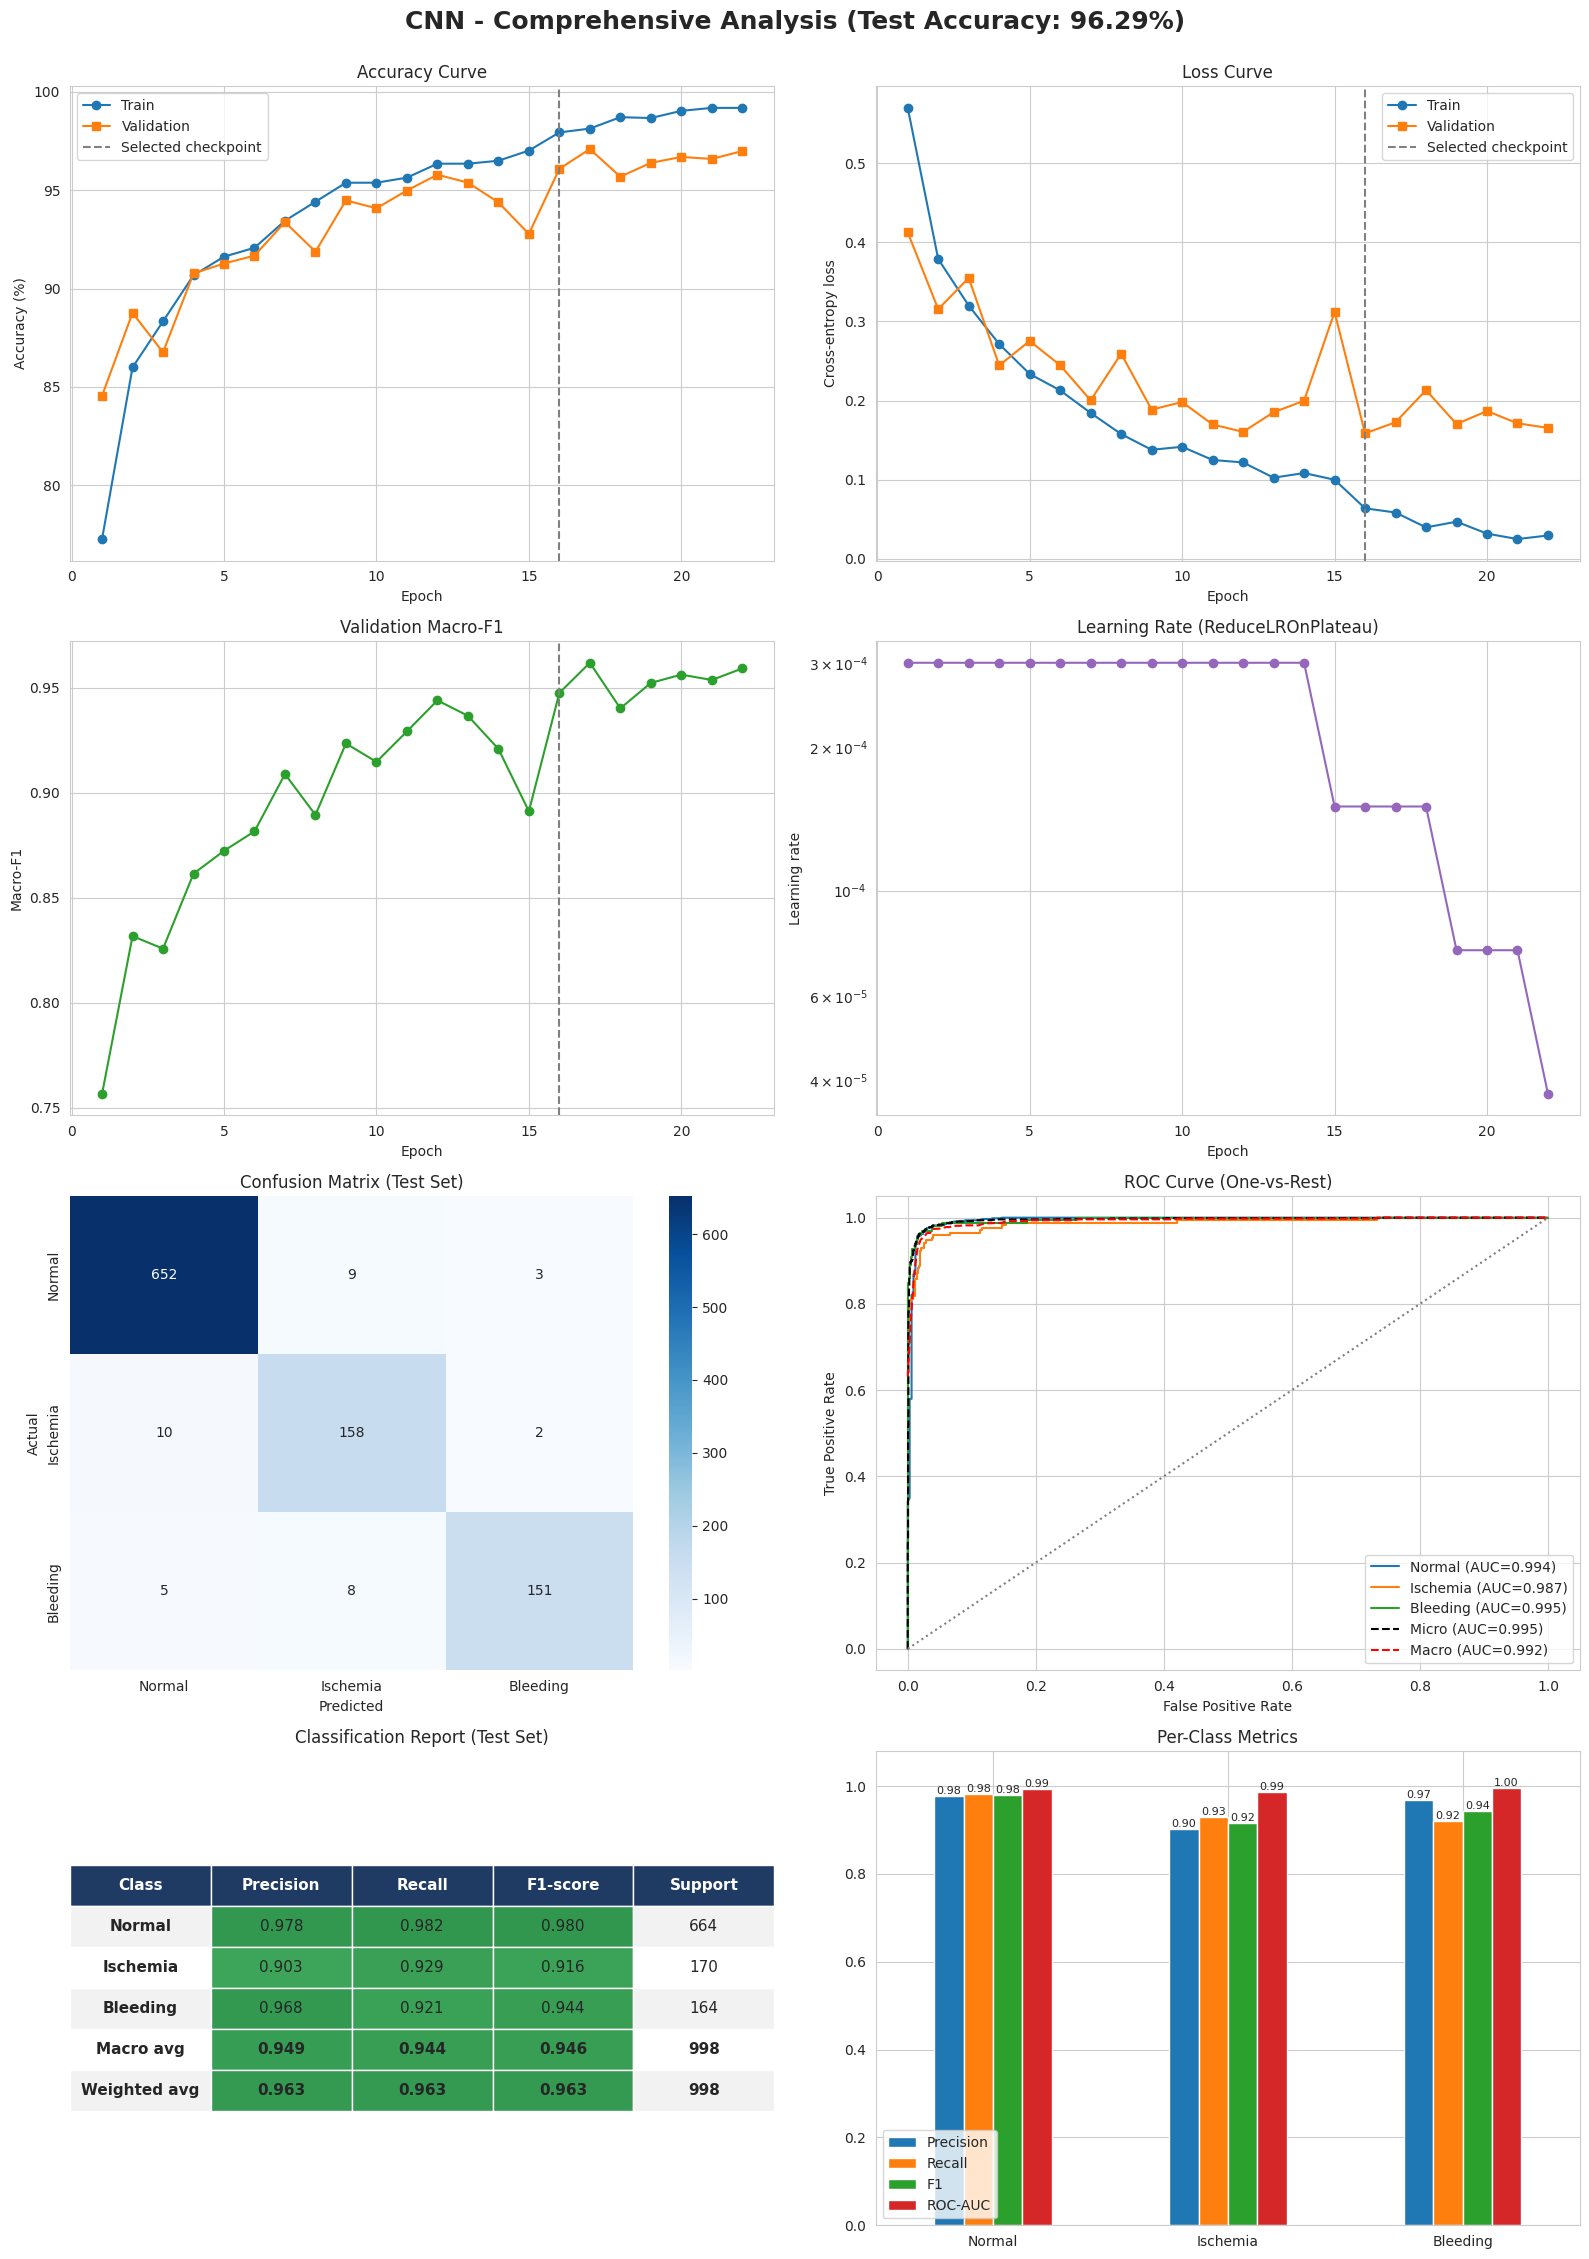

In [8]:
run_model('CNN')

[RNN] trial 0: {'lr': 0.001, 'wd': 0.0001, 'hidden': 128} -> val loss 0.3153 | val acc 0.8997 | val macro-F1 0.8515
[RNN] trial 1: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 128} -> val loss 0.2703 | val acc 0.9067 | val macro-F1 0.8679
[RNN] trial 2: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 256} -> val loss 0.2522 | val acc 0.9117 | val macro-F1 0.8844
[RNN] selected hyperparameters (lowest validation loss): {'lr': 0.0003, 'wd': 0.0001, 'hidden': 256}
[RNN] Ep 01/25 | train loss 0.6234 acc 0.7461 | val loss 0.4747 acc 0.8094 macro-F1 0.6443 | lr 3.00e-04
[RNN] Ep 02/25 | train loss 0.4222 acc 0.8440 | val loss 0.3458 acc 0.8746 macro-F1 0.8129 | lr 3.00e-04
[RNN] Ep 03/25 | train loss 0.3564 acc 0.8713 | val loss 0.4949 acc 0.8154 macro-F1 0.7895 | lr 3.00e-04
[RNN] Ep 04/25 | train loss 0.3355 acc 0.8836 | val loss 0.3920 acc 0.8686 macro-F1 0.7976 | lr 3.00e-04
[RNN] Ep 05/25 | train loss 0.2833 acc 0.8988 | val loss 0.2522 acc 0.9117 macro-F1 0.8844 | lr 3.00e-04
[RNN] Ep 06/25 | train l

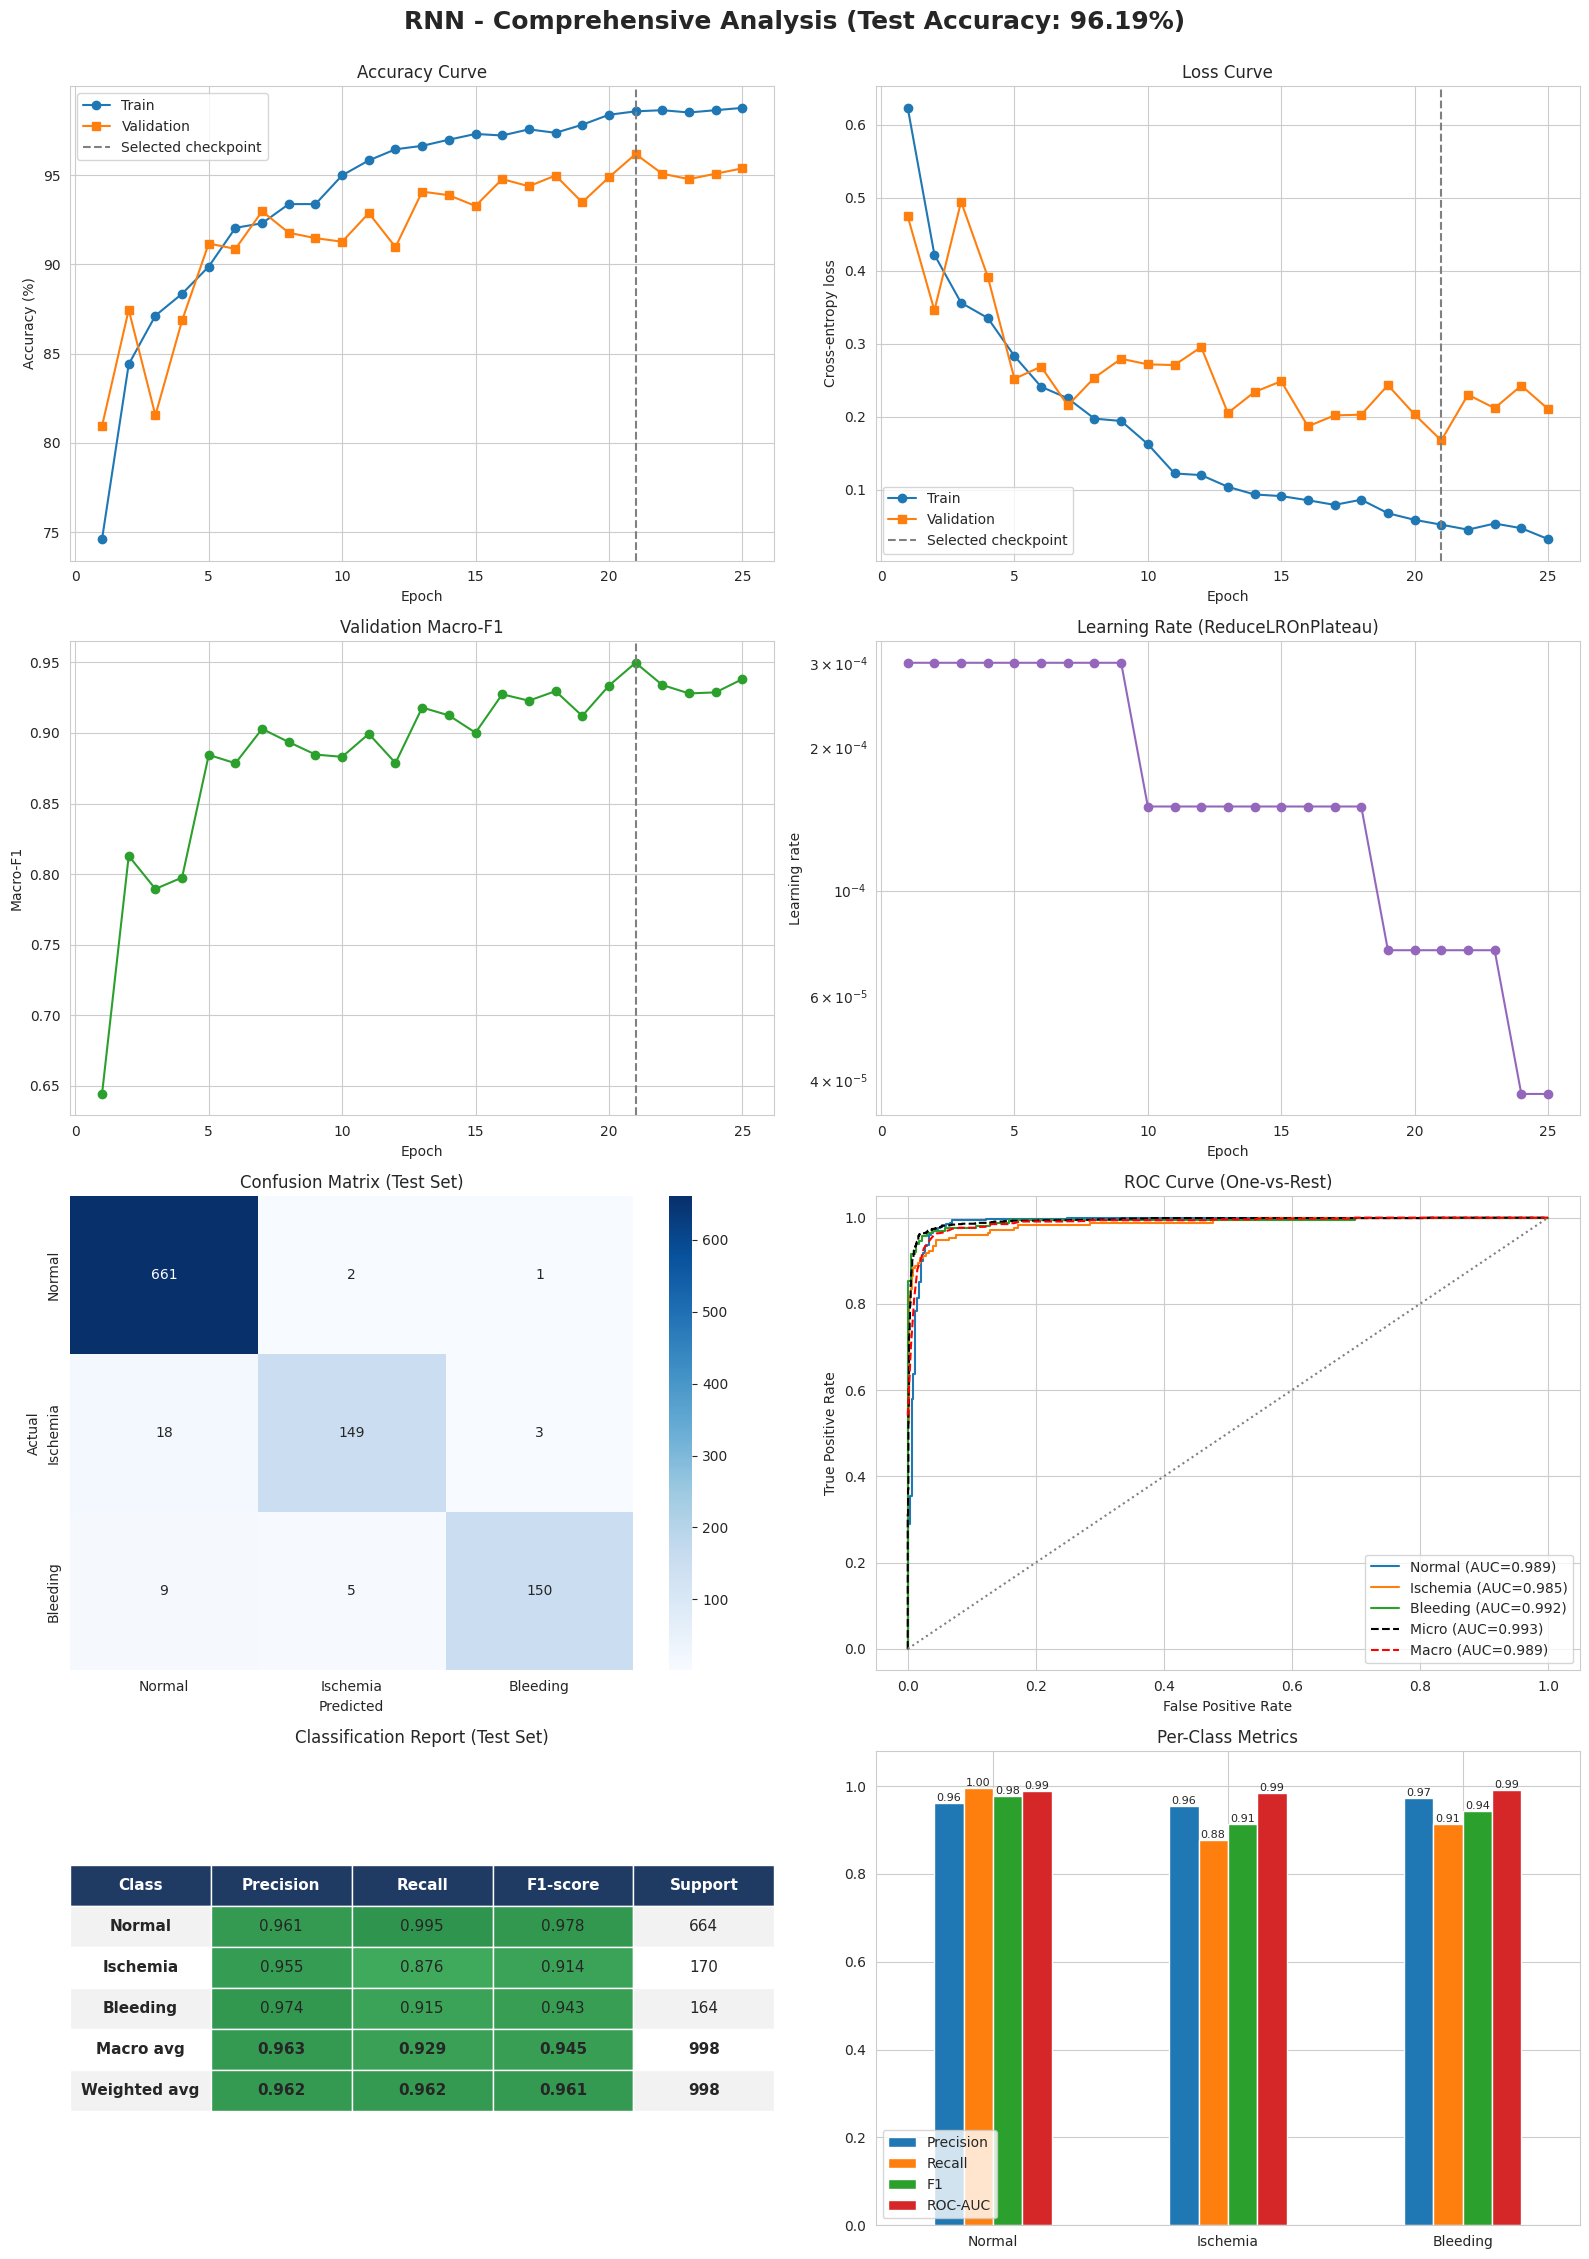

In [9]:
run_model('RNN')

[GNN] trial 0: {'lr': 0.001, 'wd': 0.0001, 'hidden': 128} -> val loss 0.3259 | val acc 0.8887 | val macro-F1 0.8513
[GNN] trial 1: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 128} -> val loss 0.2755 | val acc 0.9027 | val macro-F1 0.8643
[GNN] trial 2: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 256} -> val loss 0.2814 | val acc 0.8977 | val macro-F1 0.8413
[GNN] selected hyperparameters (lowest validation loss): {'lr': 0.0003, 'wd': 0.0001, 'hidden': 128}
[GNN] Ep 01/25 | train loss 0.6726 acc 0.7330 | val loss 0.4057 acc 0.8485 macro-F1 0.7667 | lr 3.00e-04
[GNN] Ep 02/25 | train loss 0.4417 acc 0.8382 | val loss 0.5387 acc 0.8195 macro-F1 0.6976 | lr 3.00e-04
[GNN] Ep 03/25 | train loss 0.3608 acc 0.8715 | val loss 0.3695 acc 0.8877 macro-F1 0.8332 | lr 3.00e-04
[GNN] Ep 04/25 | train loss 0.3037 acc 0.8864 | val loss 0.3956 acc 0.8596 macro-F1 0.8316 | lr 3.00e-04
[GNN] Ep 05/25 | train loss 0.2567 acc 0.9100 | val loss 0.2755 acc 0.9027 macro-F1 0.8643 | lr 3.00e-04
[GNN] Ep 06/25 | train l

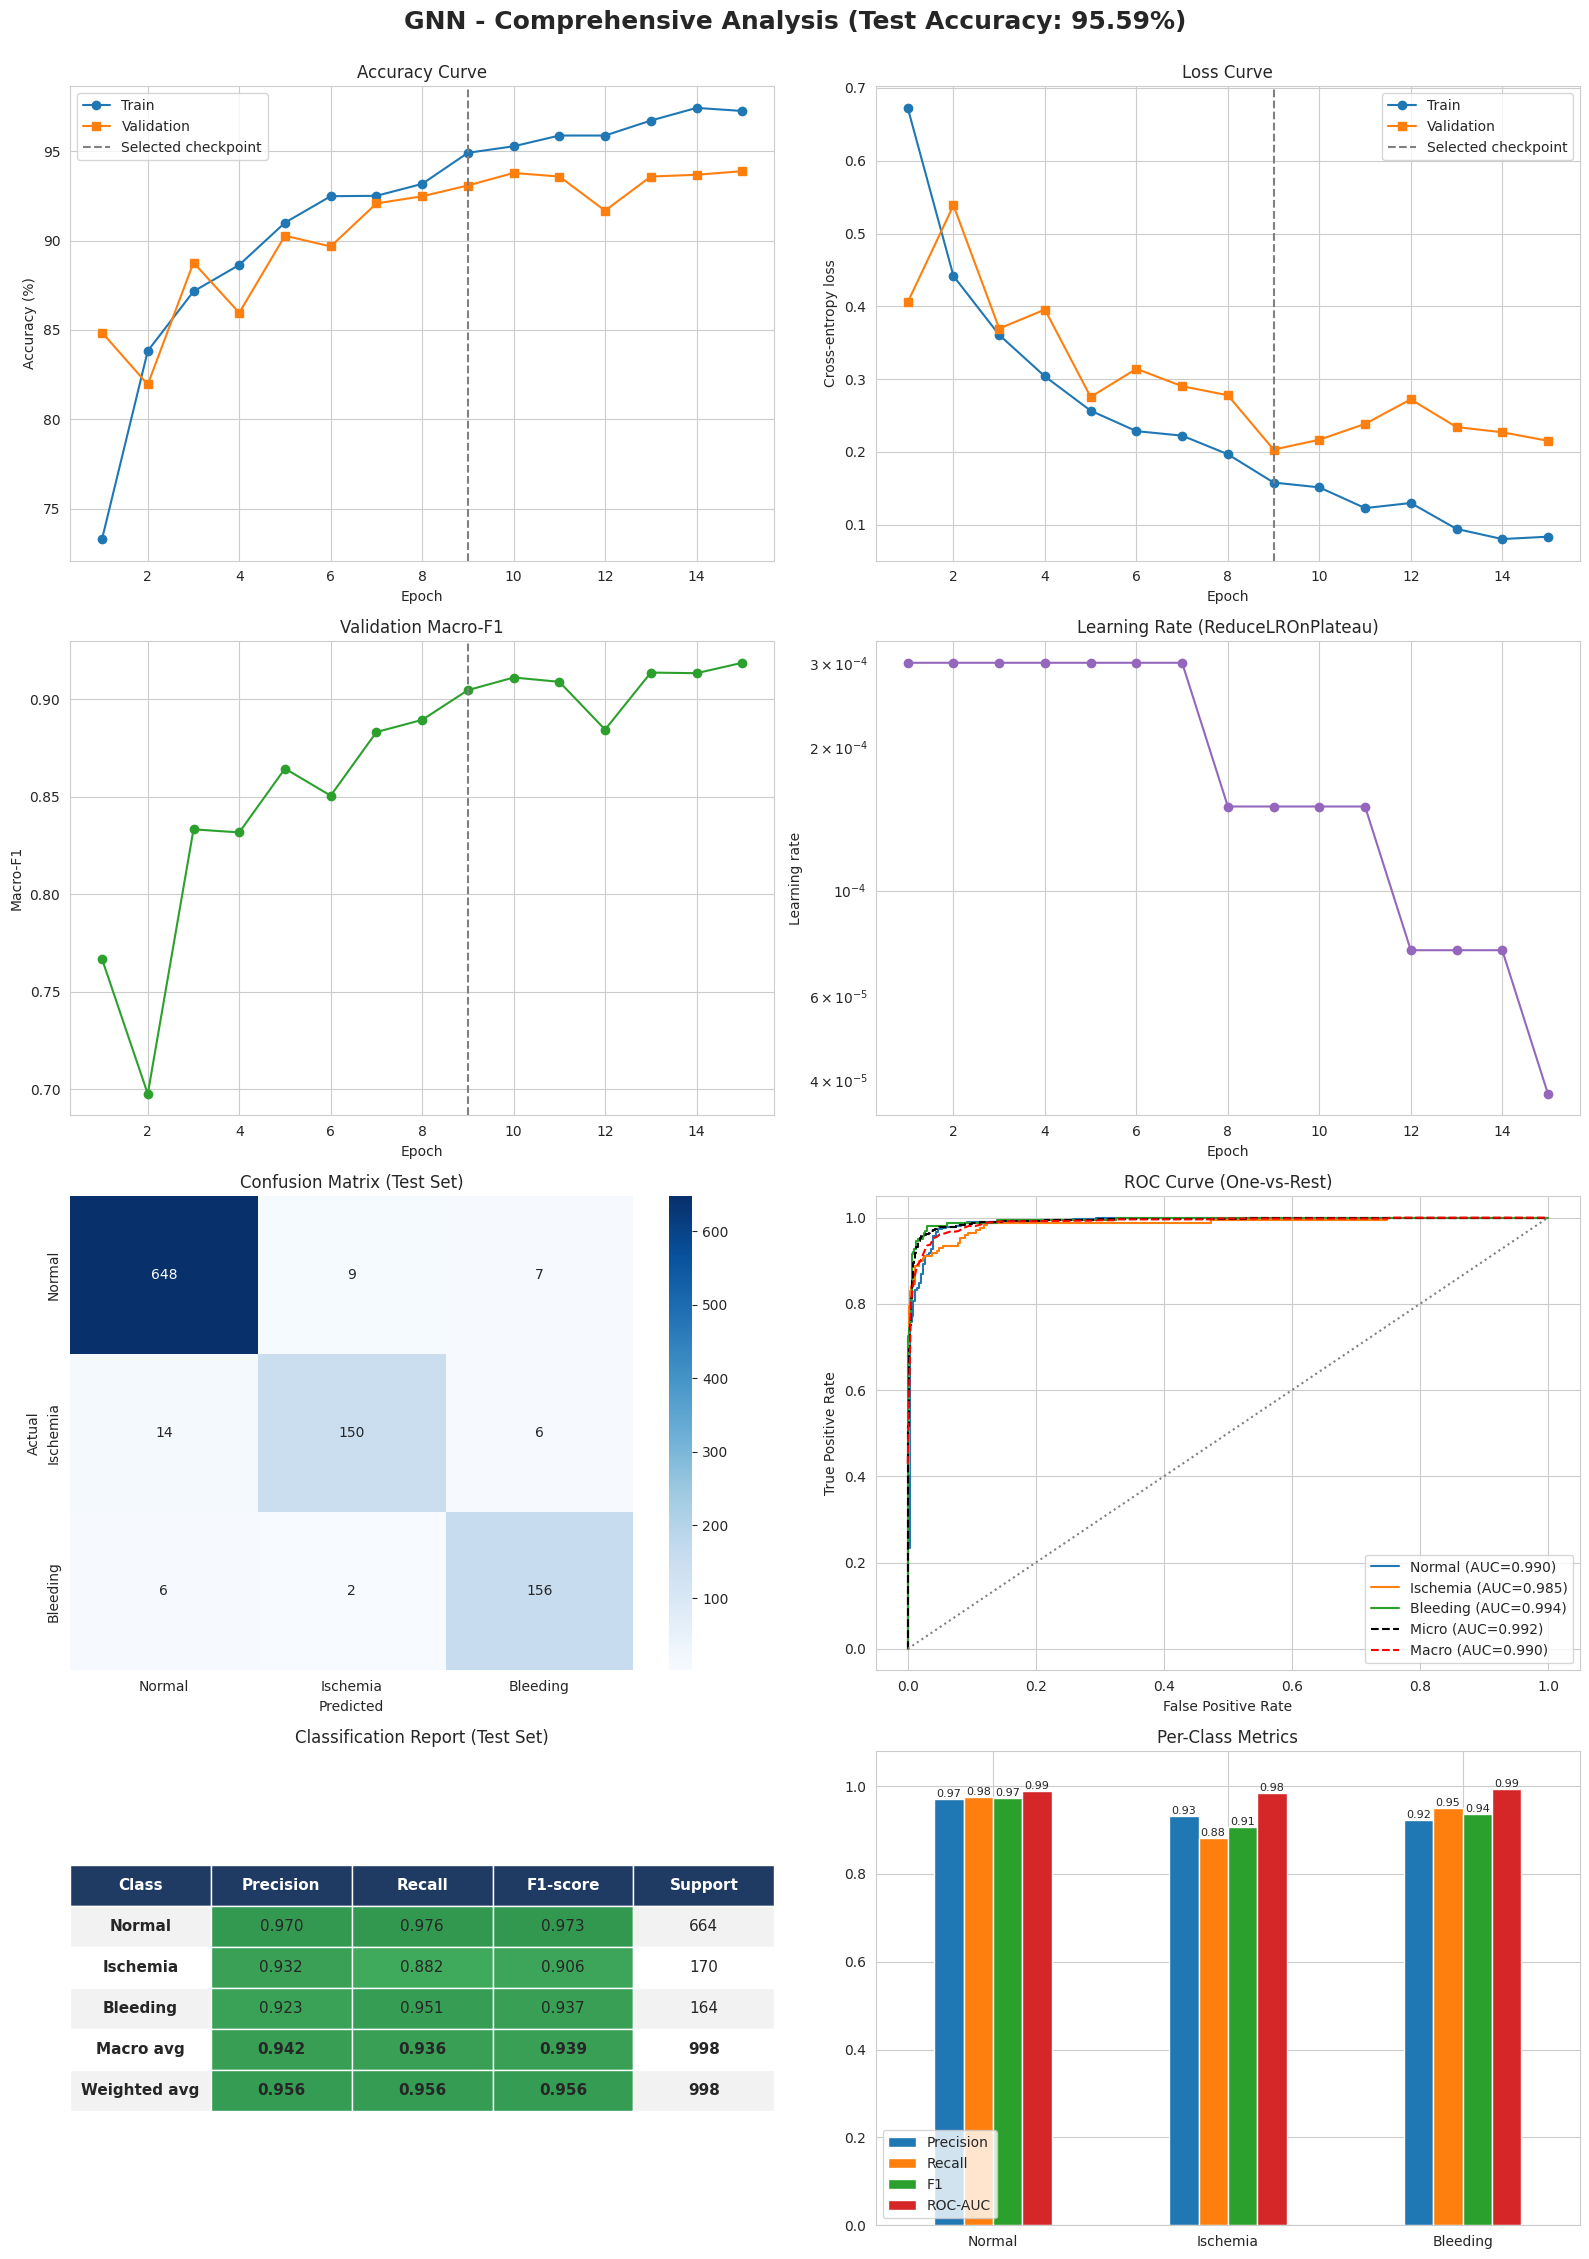

In [10]:
run_model('GNN')

[LSTM] trial 0: {'lr': 0.001, 'wd': 0.0001, 'hidden': 128} -> val loss 0.3090 | val acc 0.8907 | val macro-F1 0.8384
[LSTM] trial 1: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 128} -> val loss 0.2564 | val acc 0.9087 | val macro-F1 0.8739
[LSTM] trial 2: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 256} -> val loss 0.2807 | val acc 0.8947 | val macro-F1 0.8551
[LSTM] selected hyperparameters (lowest validation loss): {'lr': 0.0003, 'wd': 0.0001, 'hidden': 128}
[LSTM] Ep 01/25 | train loss 0.6925 acc 0.7162 | val loss 0.5343 acc 0.7653 macro-F1 0.5414 | lr 3.00e-04
[LSTM] Ep 02/25 | train loss 0.4760 acc 0.8122 | val loss 0.4545 acc 0.8164 macro-F1 0.7422 | lr 3.00e-04
[LSTM] Ep 03/25 | train loss 0.3825 acc 0.8653 | val loss 0.3277 acc 0.8877 macro-F1 0.8316 | lr 3.00e-04
[LSTM] Ep 04/25 | train loss 0.3285 acc 0.8883 | val loss 0.3095 acc 0.8957 macro-F1 0.8468 | lr 3.00e-04
[LSTM] Ep 05/25 | train loss 0.2850 acc 0.9020 | val loss 0.2564 acc 0.9087 macro-F1 0.8739 | lr 3.00e-04
[LSTM] Ep 06/25

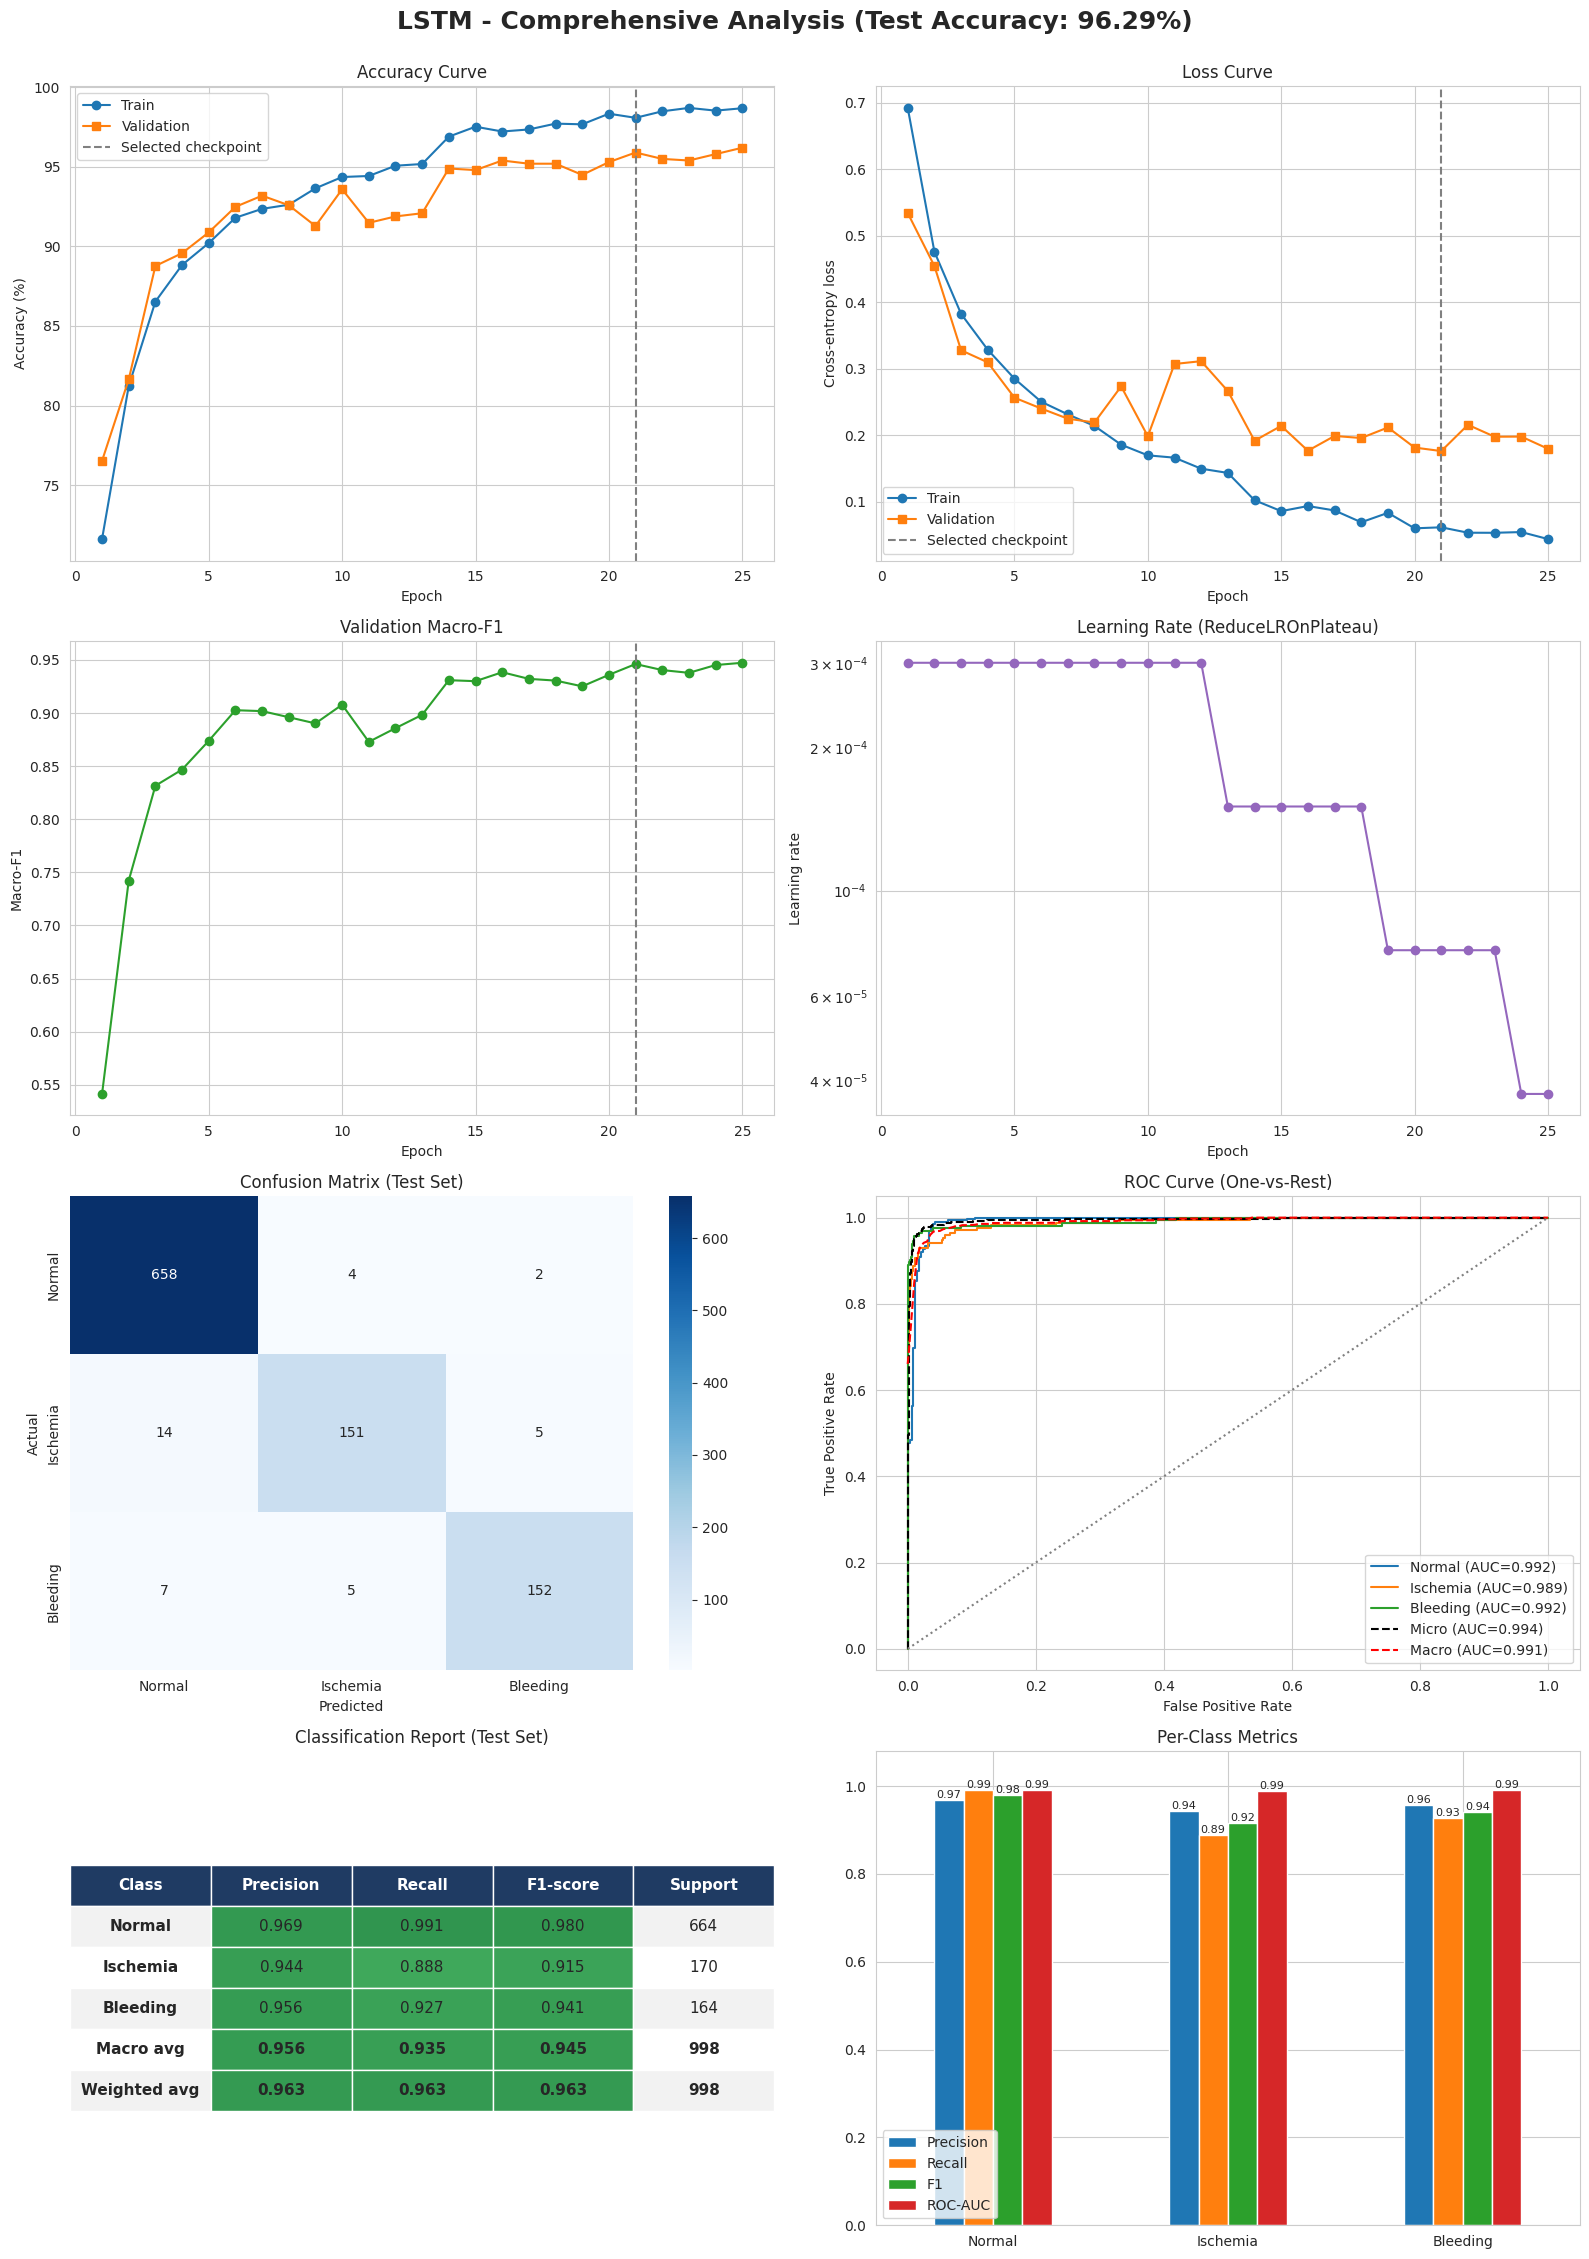

In [11]:
run_model('LSTM')

[BiLSTM] trial 0: {'lr': 0.001, 'wd': 0.0001, 'hidden': 128} -> val loss 0.3052 | val acc 0.8897 | val macro-F1 0.8350
[BiLSTM] trial 1: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 128} -> val loss 0.2758 | val acc 0.8967 | val macro-F1 0.8501
[BiLSTM] trial 2: {'lr': 0.0003, 'wd': 0.0001, 'hidden': 256} -> val loss 0.2484 | val acc 0.9107 | val macro-F1 0.8774
[BiLSTM] selected hyperparameters (lowest validation loss): {'lr': 0.0003, 'wd': 0.0001, 'hidden': 256}
[BiLSTM] Ep 01/25 | train loss 0.6630 acc 0.7242 | val loss 0.5000 acc 0.7964 macro-F1 0.6542 | lr 3.00e-04
[BiLSTM] Ep 02/25 | train loss 0.4726 acc 0.8187 | val loss 0.5068 acc 0.7854 macro-F1 0.7235 | lr 3.00e-04
[BiLSTM] Ep 03/25 | train loss 0.3830 acc 0.8574 | val loss 0.3495 acc 0.8696 macro-F1 0.8002 | lr 3.00e-04
[BiLSTM] Ep 04/25 | train loss 0.3320 acc 0.8859 | val loss 0.2783 acc 0.9017 macro-F1 0.8589 | lr 3.00e-04
[BiLSTM] Ep 05/25 | train loss 0.2796 acc 0.8995 | val loss 0.2484 acc 0.9107 macro-F1 0.8774 | lr 3.00e-

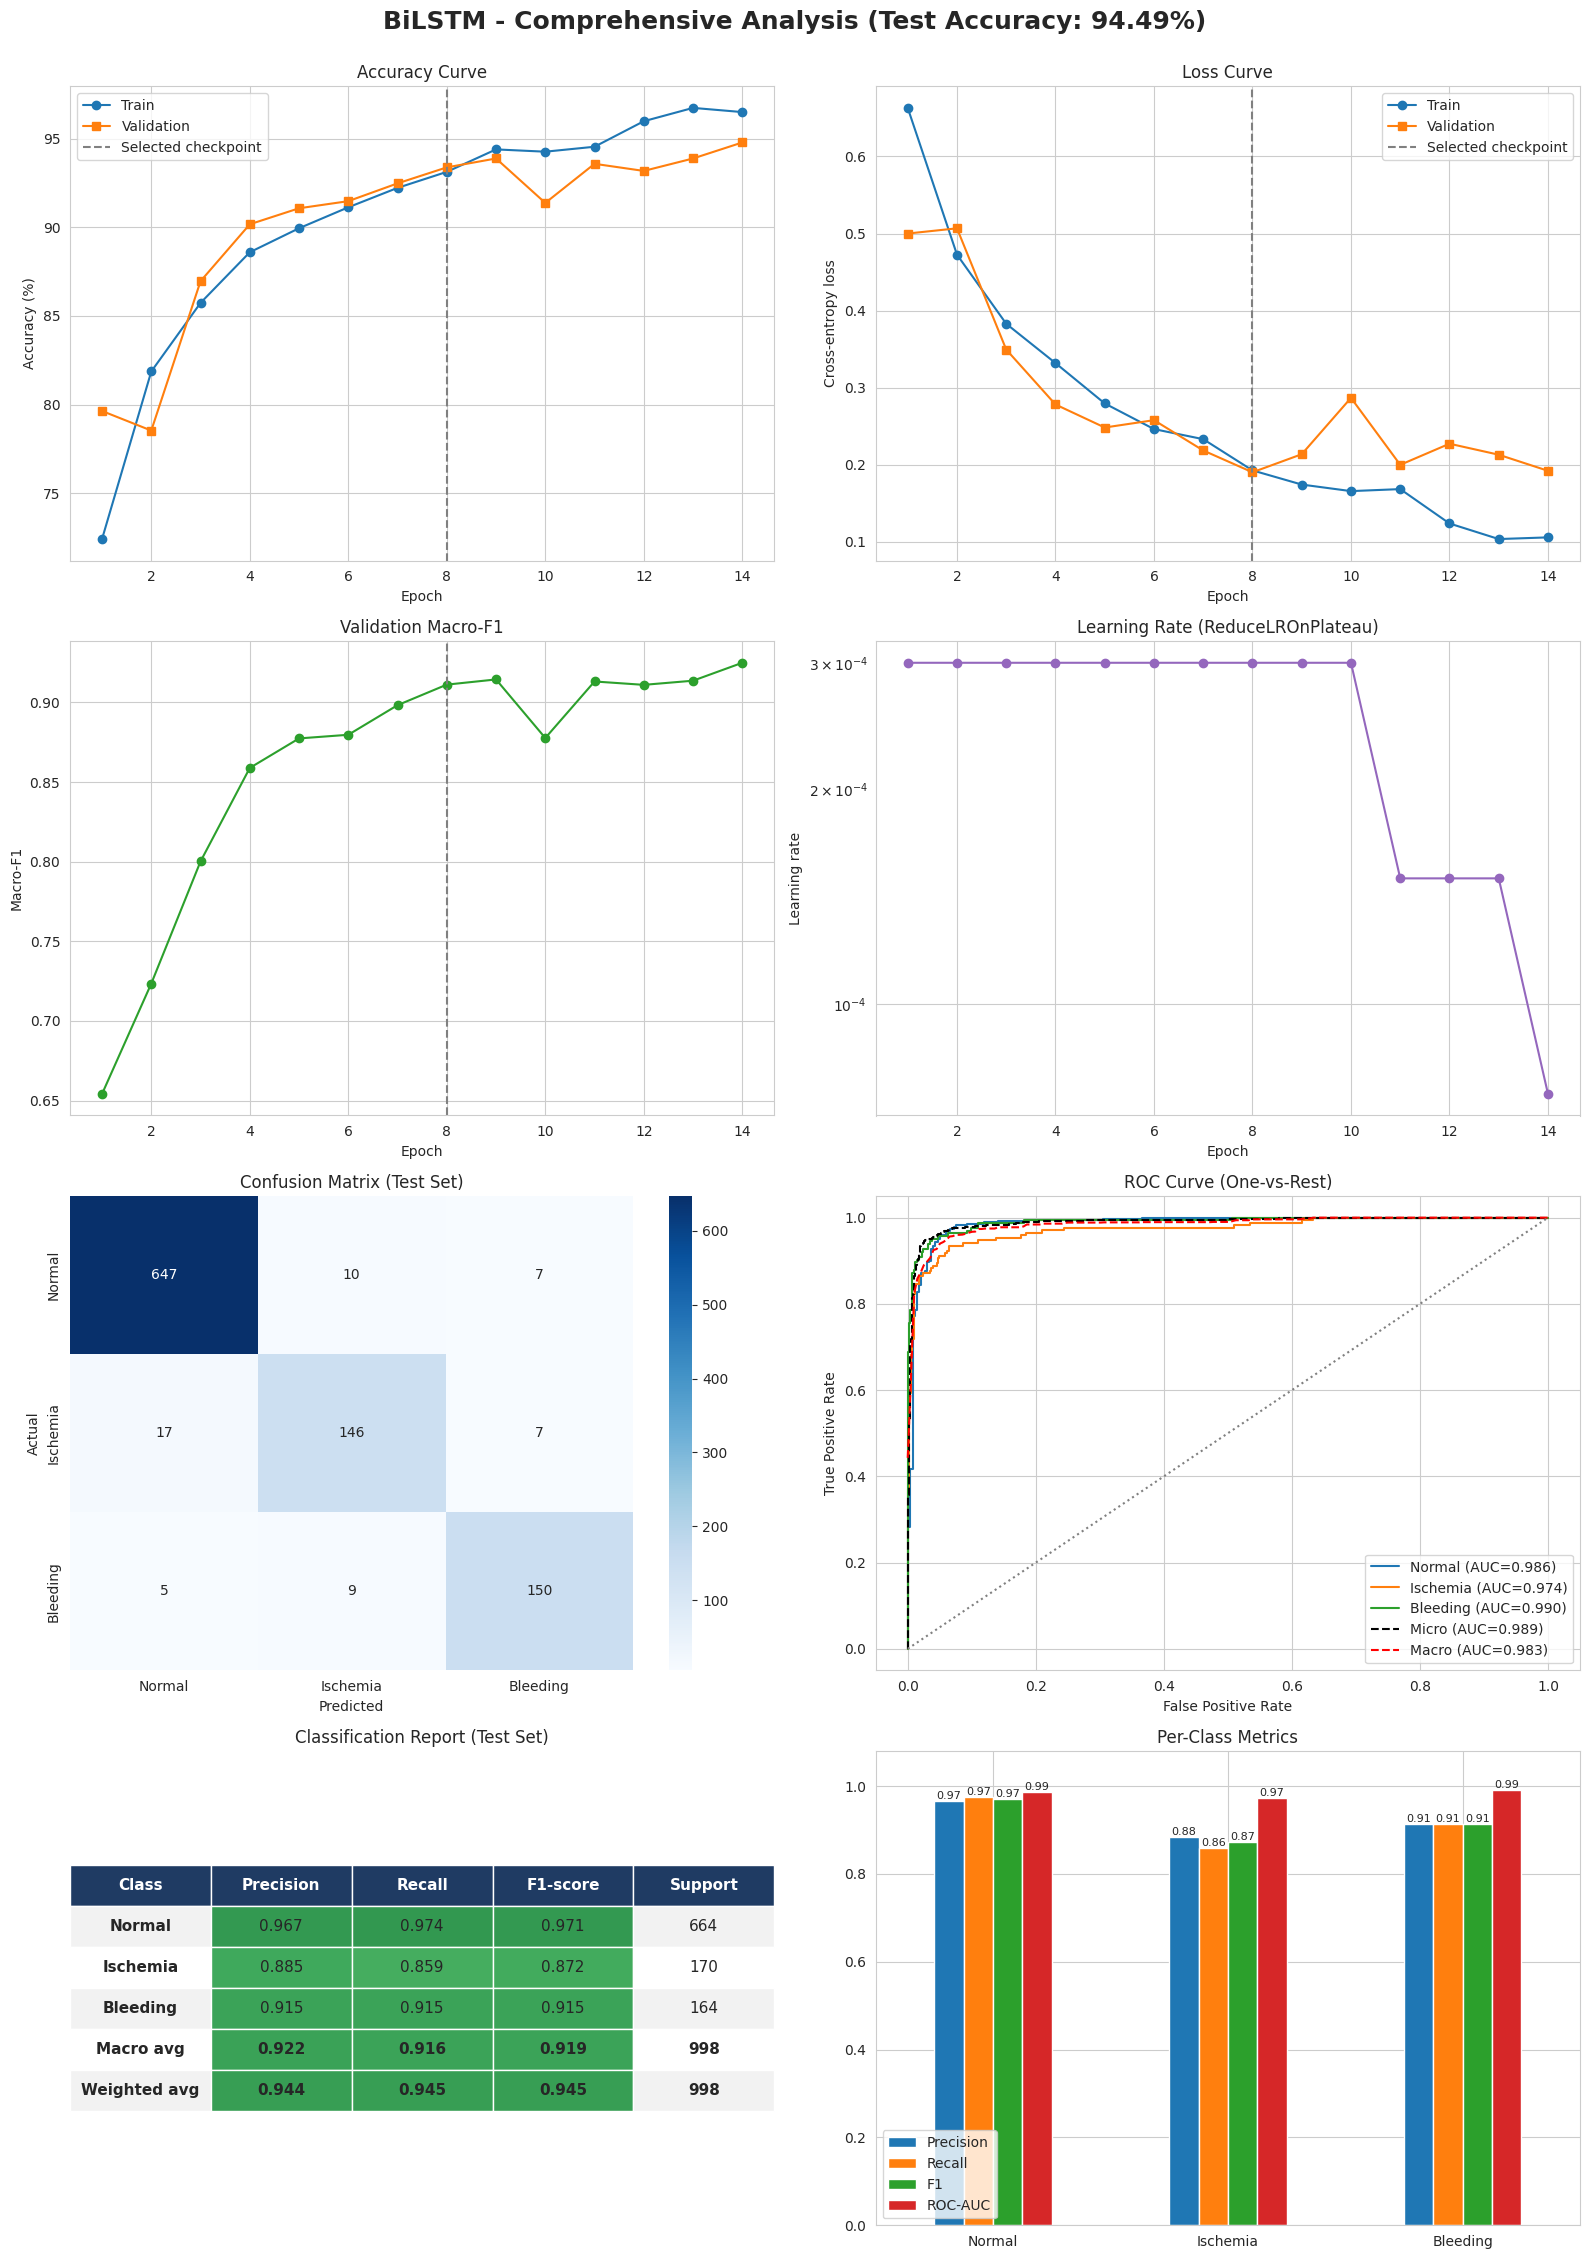

In [12]:
run_model('BiLSTM')

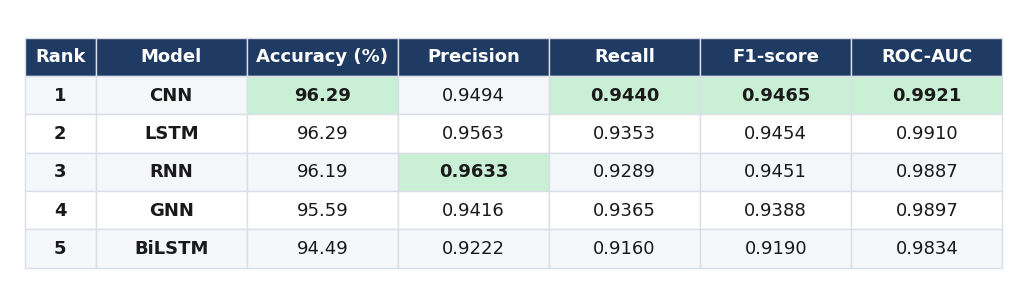

In [13]:
names = list(results)
summary = pd.DataFrame({
    n: {'Test Accuracy (%)': results[n]['acc'] * 100, 'Precision (macro)': results[n]['precision'],
        'Recall (macro)': results[n]['recall'], 'F1-score (macro)': results[n]['f1'],
        'ROC-AUC (macro)': results[n]['auc'], 'Test Loss': results[n]['test_loss'],
        'Best Val Loss': results[n]['best']['val_loss'], 'Selected Epoch': results[n]['best']['epoch'],
        'Parameters': results[n]['params'], 'Total Time (s)': results[n]['time']} for n in names}).T
summary.index.name = 'Model'
summary.to_csv(os.path.join(OUT_DIR, 'model_comparison.csv'))

metric_cols = ['Test Accuracy (%)', 'Precision (macro)', 'Recall (macro)', 'F1-score (macro)', 'ROC-AUC (macro)']
rank = summary.sort_values('Test Accuracy (%)', ascending=False)
best_in_col = {c: rank[c].astype(float).idxmax() for c in metric_cols}

col_labels = ['Rank', 'Model', 'Accuracy (%)', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
cell_text = [[str(k + 1), n, f'{rank.loc[n, metric_cols[0]]:.2f}'] + [f'{rank.loc[n, c]:.4f}' for c in metric_cols[1:]]
             for k, n in enumerate(rank.index)]

fig, ax = plt.subplots(figsize=(13, 0.62 * (len(rank) + 1)))
fig.patch.set_facecolor('white'); ax.axis('off')
tbl = ax.table(cellText=cell_text, colLabels=col_labels, cellLoc='center', loc='center',
               colWidths=[0.07, 0.15, 0.15, 0.15, 0.15, 0.15, 0.15])
tbl.auto_set_font_size(False); tbl.set_fontsize(13); tbl.scale(1, 2.3)
for (i, j), cell in tbl.get_celld().items():
    cell.set_edgecolor('#d9dee7')
    if i == 0:
        cell.set_facecolor('#1f3b63'); cell.get_text().set_color('white'); cell.get_text().set_weight('bold')
    else:
        cell.set_facecolor('#f5f7fa' if i % 2 else 'white'); cell.get_text().set_color('#1a1a1a')
        if j <= 1: cell.get_text().set_weight('bold')
        if j >= 2 and rank.index[i - 1] == best_in_col[metric_cols[j - 2]]:
            cell.set_facecolor('#c9efd5'); cell.get_text().set_weight('bold')
save_fig(fig, 'comparison_table.png'); plt.show()

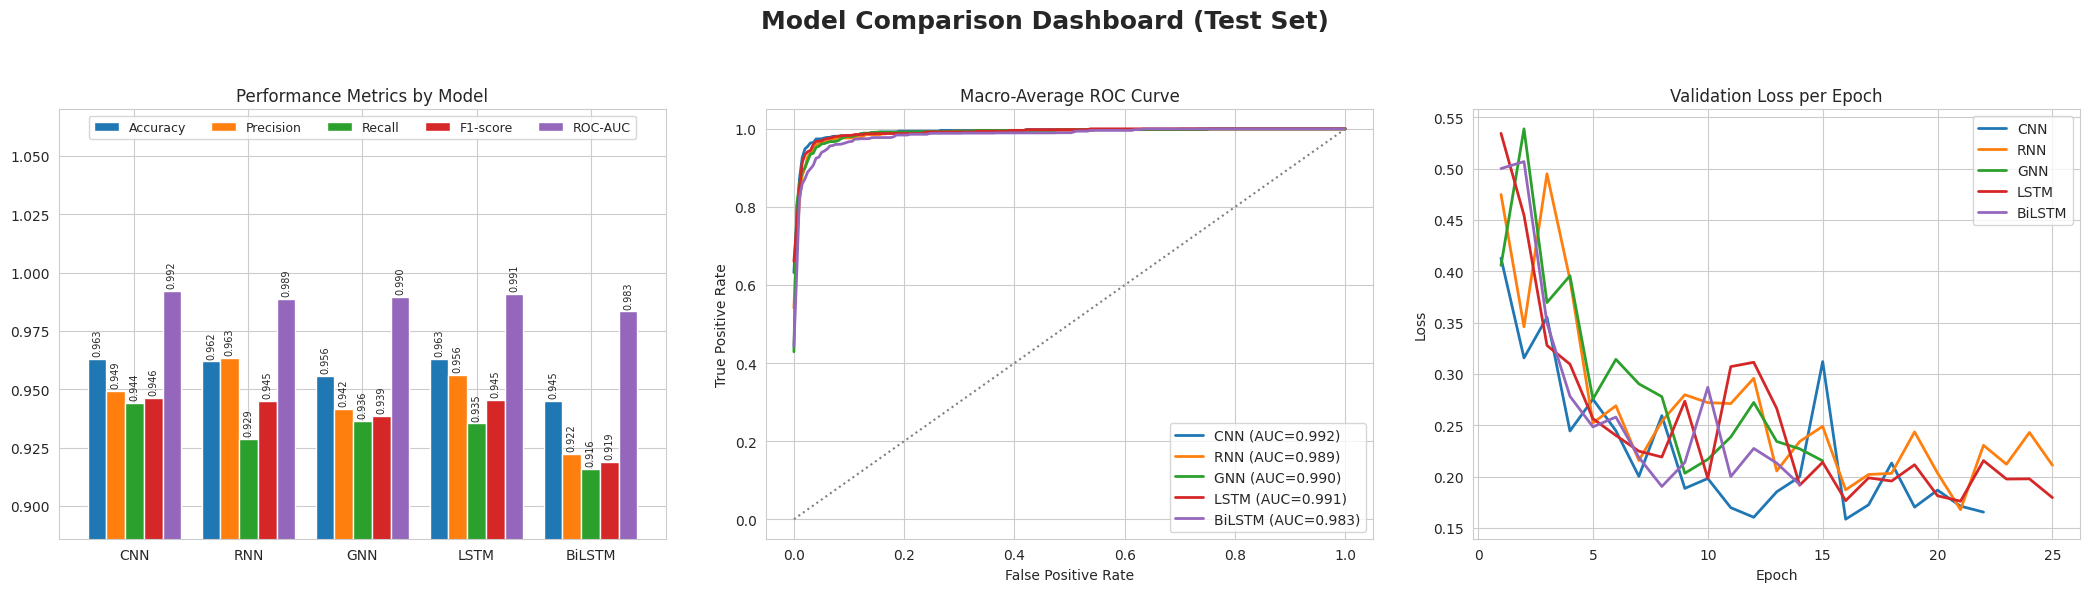

In [14]:
colors = plt.cm.tab10(np.arange(len(names)))
fig, ax = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle('Model Comparison Dashboard (Test Set)', fontsize=18, fontweight='bold')

pdf = summary[metric_cols].astype(float).copy()
pdf['Test Accuracy (%)'] = pdf['Test Accuracy (%)'] / 100
pdf.columns = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
pdf.plot(kind='bar', ax=ax[0], width=0.82, rot=0, ylim=(max(0, pdf.values.min() - 0.03), 1.07))
for c in ax[0].containers: ax[0].bar_label(c, fmt='%.3f', fontsize=7, rotation=90, padding=2)
ax[0].set_title('Performance Metrics by Model'); ax[0].set_xlabel(''); ax[0].legend(ncol=5, fontsize=9, loc='upper center')

for n, col in zip(names, colors):
    f, t, s = results[n]['roc']['macro']
    ax[1].plot(f, t, color=col, lw=2, label=f'{n} (AUC={s:.3f})')
ax[1].plot([0, 1], [0, 1], 'gray', ls=':')
ax[1].set(title='Macro-Average ROC Curve', xlabel='False Positive Rate', ylabel='True Positive Rate'); ax[1].legend(loc='lower right')

for n, col in zip(names, colors):
    h = results[n]['history']
    ax[2].plot(np.arange(1, len(h['val_loss']) + 1), h['val_loss'], color=col, lw=2, label=n)
ax[2].set(title='Validation Loss per Epoch', xlabel='Epoch', ylabel='Loss'); ax[2].legend()
plt.tight_layout(rect=[0, 0, 1, 0.94]); save_fig(fig, 'comparison_dashboard.png'); plt.show()

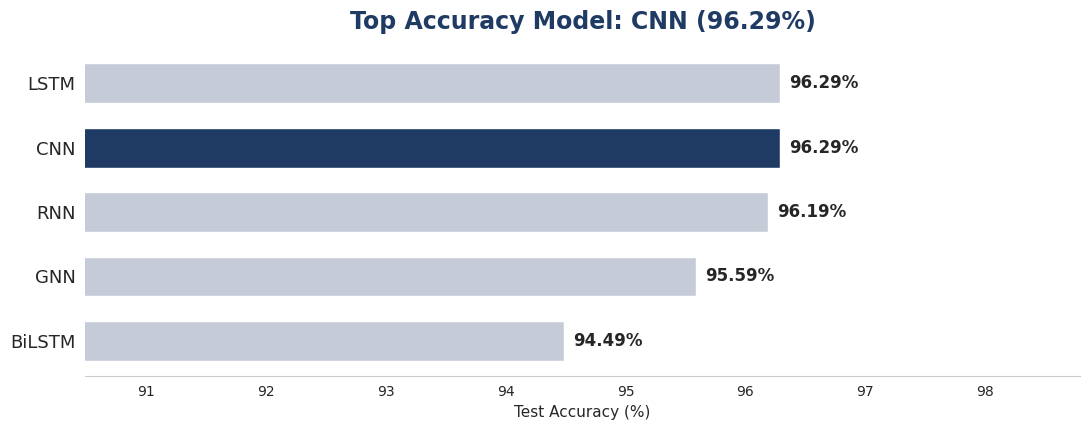

Top accuracy model: CNN (96.29%)


In [15]:
top = summary['Test Accuracy (%)'].astype(float).idxmax()
r = results[top]
vals = summary['Test Accuracy (%)'].astype(float).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 0.9 + 0.7 * len(vals)))
fig.patch.set_facecolor('white')
bars = ax.barh(list(vals.index), vals.values, height=0.62,
               color=['#1f3b63' if n == top else '#c5ccd8' for n in vals.index])
ax.bar_label(bars, labels=[f'{v:.2f}%' for v in vals.values], padding=6, fontsize=12, fontweight='bold')
ax.set_xlim(max(0, vals.min() - 4), min(vals.max() + 2.5, 101))
ax.set_xlabel('Test Accuracy (%)', fontsize=11)
ax.tick_params(axis='y', labelsize=13)
for sp in ('top', 'right', 'left'): ax.spines[sp].set_visible(False)
ax.grid(False)
ax.set_title(f'Top Accuracy Model: {top} ({r["acc"]*100:.2f}%)', fontsize=17, fontweight='bold', color='#1f3b63', pad=14)
plt.tight_layout(); save_fig(fig, 'top_model.png'); plt.show()
print(f'Top accuracy model: {top} ({r["acc"]*100:.2f}%)')